# Handwritten Alphabet Recognition Using CNN
**Project:** Machine Learning – CodeAlpha  
**Student:** Raza Ali

## Project objective
Build a Convolutional Neural Network (CNN) that recognizes one handwritten uppercase English letter (A–Z) from a 28×28 grayscale image.

This notebook follows the complete workflow: environment setup, EMNIST dataset loading, preprocessing, train/validation/test split, CNN training, evaluation, custom-image testing, model saving, and an optional Gradio demo.

**Execution note:** Run the notebook from top to bottom in a fresh Google Colab runtime. The notebook uses the GPU when one is available, but it can also run on CPU (more slowly).

## 1. Import libraries and check the runtime

The next cells import the libraries used throughout the project and check whether TensorFlow can detect a GPU. The GPU check does not activate or provide a GPU; the Colab runtime must already be configured for one.

In [1]:
import os
import string
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

gpus = tf.config.list_physical_devices('GPU')
print("GPU available:", len(gpus) > 0)
print("GPU devices:", gpus)

TensorFlow: 2.21.0
NumPy: 2.4.6
Scikit-learn: 1.6.1
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
if tf.config.list_physical_devices('GPU'):
    !nvidia-smi

Sat Nov 21 18:31:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Connect Google Drive and prepare the project folder

The trained model will be saved to Google Drive so it remains available after a Colab runtime disconnects.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

project_folder = '/content/drive/MyDrive/Handwritten_Alphabet_Project'
os.makedirs(project_folder, exist_ok=True)

model_path = os.path.join(project_folder, 'handwritten_alphabet_model.keras')

print("Project folder:", project_folder)
print("Model will be saved to:", model_path)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Handwritten_Alphabet_Project
Model will be saved to: /content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model.keras


## 3. Install and load the EMNIST Letters dataset

EMNIST Letters contains 28×28 grayscale character images. We load its training partition and create our own reproducible 80/10/10 split.

The original TFDS test partition available in the earlier project run did not contain all 26 letter labels. Therefore, the final evaluation uses a held-out test subset from the training partition, ensuring all 26 classes are represented.

In [4]:
!pip -q install tensorflow-datasets importlib_resources
import tensorflow_datasets as tfds

train_raw, dataset_info = tfds.load(
    'emnist/letters',
    split='train',
    as_supervised=True,
    with_info=True
)

print("Training-partition examples:", dataset_info.splits['train'].num_examples)
print("Image shape:", dataset_info.features['image'].shape)
print("Dataset metadata classes:", dataset_info.features['label'].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.80BNBP_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.80BNBP_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.
Training-partition examples: 88800
Image shape: (28, 28, 1)
Dataset metadata classes: 37


## 4. Explore the dataset and verify its labels

The dataset metadata may describe additional label values, so we inspect the labels actually present in the training partition. EMNIST Letters uses labels 1–26 for A–Z; preprocessing converts them to 0–25 for the CNN.

In [5]:
train_labels = np.concatenate([
    labels.numpy()
    for _, labels in train_raw.batch(10000)
])

unique_labels, label_counts = np.unique(train_labels, return_counts=True)

print("Labels present:", unique_labels)
print("Number of letter classes:", len(unique_labels))
print("Label names:", list(string.ascii_uppercase))

Labels present: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26]
Number of letter classes: 26
Label names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


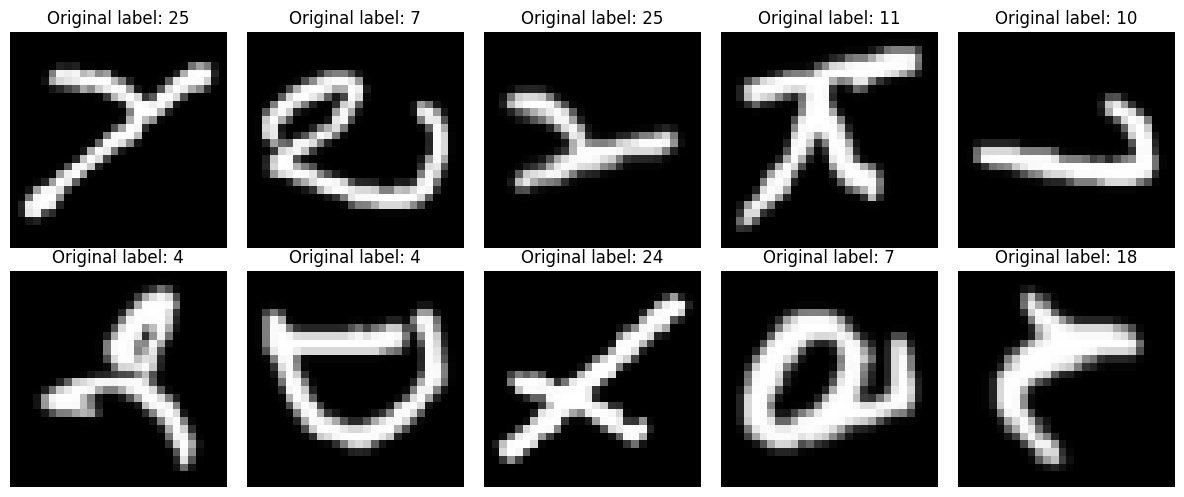

In [6]:
plt.figure(figsize=(12, 5))

for i, (image, label) in enumerate(train_raw.take(10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.numpy().squeeze(), cmap='gray')
    plt.title(f"Original label: {label.numpy()}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Preprocess the images

The EMNIST images need to be transposed to display the letters upright. Pixel values are normalized from 0–255 to 0–1, and labels are shifted from 1–26 to 0–25.

In [7]:
def preprocess_image(image, label):
    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.cast(image, tf.float32) / 255.0
    label = label - 1
    return image, label

In [8]:
for image, label in train_raw.take(1):
    processed_image, processed_label = preprocess_image(image, label)
    print("Processed image shape:", processed_image.shape)
    print("Pixel range:", float(tf.reduce_min(processed_image)), "to", float(tf.reduce_max(processed_image)))
    print("Processed label:", int(processed_label))

Processed image shape: (28, 28, 1)
Pixel range: 0.0 to 1.0
Processed label: 24


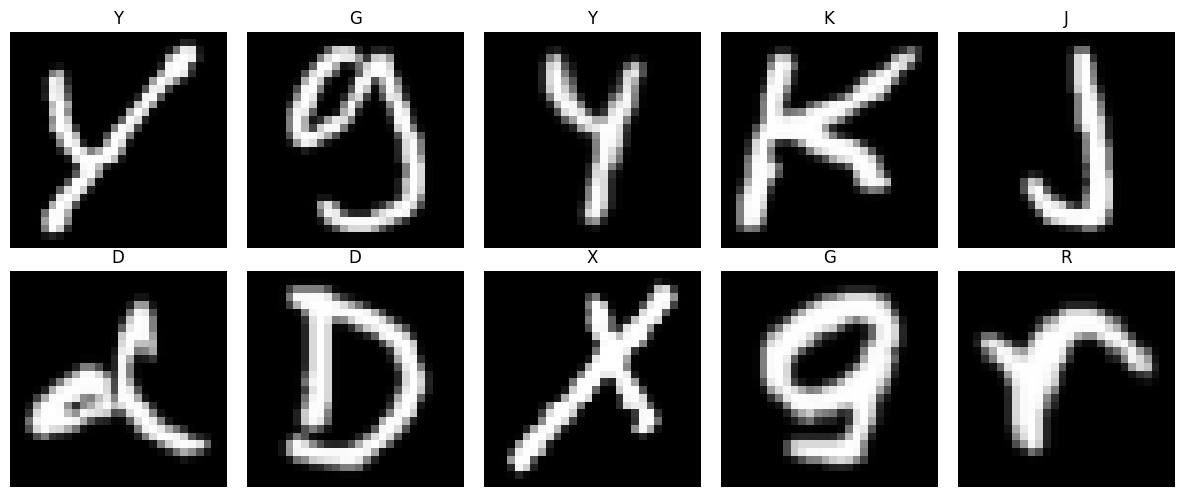

In [9]:
plt.figure(figsize=(12, 5))

for i, (image, label) in enumerate(train_raw.take(10)):
    processed_image, processed_label = preprocess_image(image, label)
    plt.subplot(2, 5, i + 1)
    plt.imshow(processed_image.numpy().squeeze(), cmap='gray')
    plt.title(string.ascii_uppercase[int(processed_label)])
    plt.axis('off')

plt.tight_layout()
plt.show()

## 6. Create training, validation, and test datasets

We shuffle the 88,800 examples with a fixed seed and split them into:
- 71,040 training examples (80%)
- 8,880 validation examples (10%)
- 8,880 held-out test examples (10%)

The test set is kept separate from training and validation. Batching and prefetching help TensorFlow feed data efficiently to the model.

In [10]:
shuffled_raw = train_raw.shuffle(
    88800,
    seed=42,
    reshuffle_each_iteration=False
)

train_raw_new = shuffled_raw.take(71040)
validation_raw_new = shuffled_raw.skip(71040).take(8880)
test_raw_new = shuffled_raw.skip(79920)

BATCH_SIZE = 128

train_data = (
    train_raw_new
    .map(preprocess_image)
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

validation_data = (
    validation_raw_new
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_data = (
    test_raw_new
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training examples:", 71040)
print("Validation examples:", 8880)
print("Testing examples:", 8880)

Training examples: 71040
Validation examples: 8880
Testing examples: 8880


In [11]:
for images, labels in train_data.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)

Batch image shape: (128, 28, 28, 1)
Batch label shape: (128,)


## 7. Build the CNN model

The CNN uses two convolutional layers to learn visual patterns, max-pooling to reduce spatial dimensions, and dense layers to classify the image into one of 26 letters.

In [12]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(26, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,098 (887.10 KB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the model

The model is trained for 10 epochs. Validation data is used to monitor performance during training; the held-out test data is not used for model fitting.

In [13]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10
)

Epoch 1/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 32s 26ms/step - accuracy: 0.7206 - loss: 0.9139 - val_accuracy: 0.8815 - val_loss: 0.3831
Epoch 2/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8628 - loss: 0.4279 - val_accuracy: 0.9054 - val_loss: 0.3033
Epoch 3/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.8862 - loss: 0.3519 - val_accuracy: 0.9145 - val_loss: 0.2604
Epoch 4/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8998 - loss: 0.3070 - val_accuracy: 0.9218 - val_loss: 0.2442
Epoch 5/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9094 - loss: 0.2757 - val_accuracy: 0.9297 - val_loss: 0.2265
Epoch 6/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.9155 - loss: 0.2526 - val_accuracy: 0.9291 - val_loss: 0.2198
Epoch 7/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9211 - loss: 0.2309 - val_accuracy: 0.9286 - val_loss: 0.2210
Epoch 8/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9262 - loss: 0.2157 - val_accur

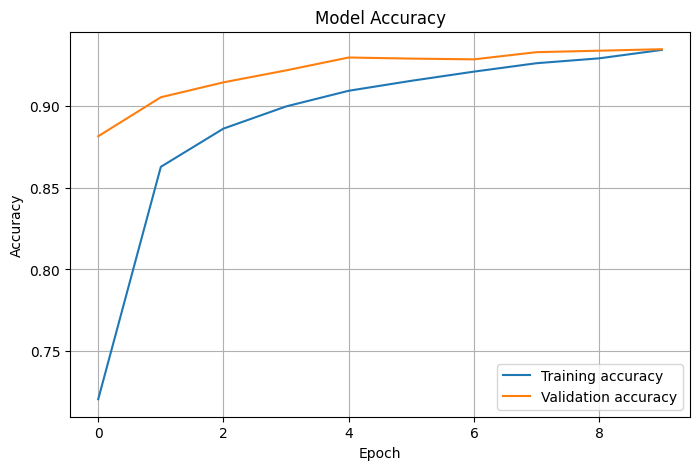

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

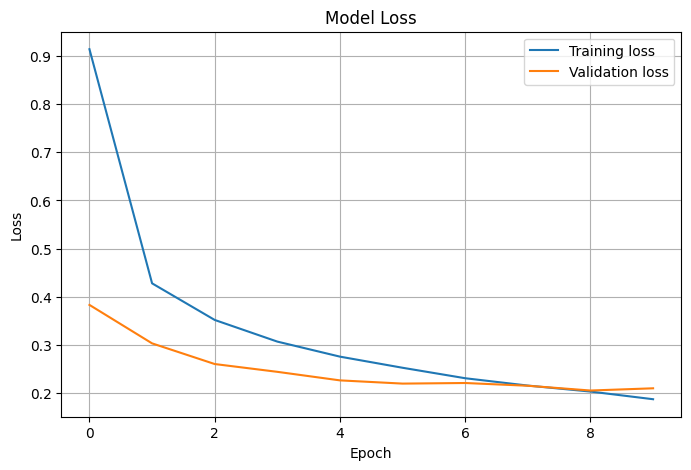

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

## 9. Save the trained model to Google Drive

Save immediately after training. This protects the trained model if the Colab runtime disconnects.

In [16]:
model.save(model_path)
print("Model saved:", os.path.exists(model_path))
print("Saved model path:", model_path)

Model saved: True
Saved model path: /content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model.keras


## 10. Evaluate the model on the held-out test set

This is the final evaluation on examples that were not used for training or validation.

In [17]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9350 - loss: 0.2010
Test Accuracy: 93.5 %
Test Loss: 0.201


## 11. Classification report and confusion matrix

The classification report shows precision, recall, and F1-score for each letter. The confusion matrix shows which letters the model most often mixes up.

70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
              precision    recall  f1-score   support

           A       0.87      0.96      0.91       336
           B       0.98      0.95      0.97       333
           C       0.98      0.97      0.98       340
           D       0.94      0.96      0.95       317
           E       0.97      0.97      0.97       325
           F       0.98      0.96      0.97       341
           G       0.86      0.83      0.84       349
           H       0.95      0.97      0.96       333
           I       0.77      0.68      0.72       364
           J       0.93      0.96      0.94       339
           K       0.98      0.96      0.97       340
           L       0.71      0.78      0.74       349
           M       1.00      0.97      0.98       344
           N       0.95      0.97      0.96       338
           O       0.96      0.98      0.97       340
           P       0.98      0.98      0.98       363
           Q       0.86      0.86      0.

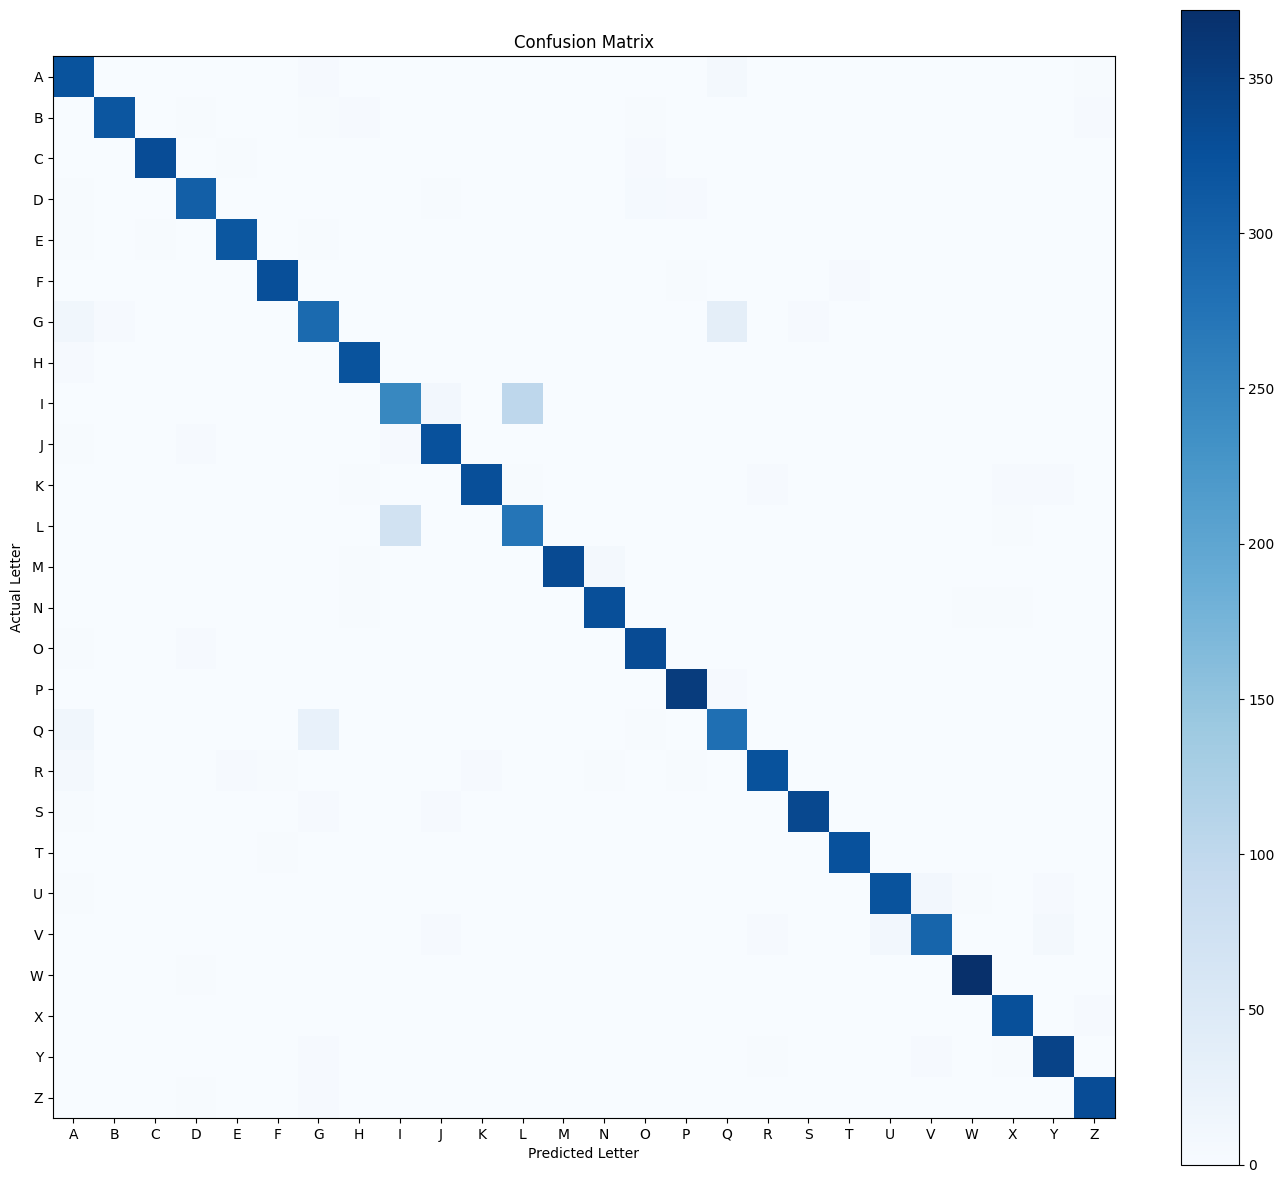

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

class_names = list(string.ascii_uppercase)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_data
])

y_probabilities = model.predict(test_data)
y_pred = np.argmax(y_probabilities, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(26)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=range(26))

plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Letter')
plt.ylabel('Actual Letter')
plt.xticks(range(26), class_names)
plt.yticks(range(26), class_names)
plt.colorbar()
plt.tight_layout()
plt.show()

## 12. Test the model with a custom handwritten image

Upload an image containing one or more clearly separated handwritten uppercase letters. The cell below detects separate letter regions, orders them row by row, converts each region to the model's 28×28 input format, and predicts the letters.

This custom-image test is a demonstration, not a replacement for the held-out test-set evaluation.

Saving Screenshot 2026-11-19 061126.png to Screenshot 2026-11-19 061126.png
Corrected reading order: top row, then bottom row


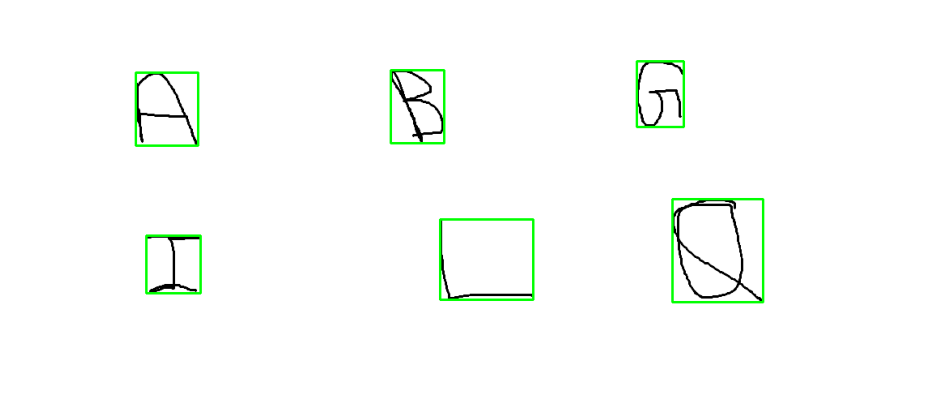

Detected letter regions: 6


In [19]:
from google.colab import files
from PIL import Image
import cv2

uploaded = files.upload()
image_path = next(iter(uploaded))

image = cv2.imread(image_path)
if image is None:
    raise ValueError("The uploaded image could not be read.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, threshold = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

contours, _ = cv2.findContours(
    threshold,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

letter_boxes = []

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    if w > 10 and h > 10:
        letter_boxes.append((x, y, w, h))

if not letter_boxes:
    raise ValueError("No letter regions were detected.")


# Sort detected letters into top and bottom rows
vertical_positions = sorted(
    letter_boxes,
    key=lambda box: box[1] + box[3] / 2
)

if len(vertical_positions) != 6:
    raise ValueError(f"Expected 6 letters, detected {len(vertical_positions)}.")

centers_y = [y + h / 2 for x, y, w, h in vertical_positions]

gaps = [
    centers_y[i + 1] - centers_y[i]
    for i in range(len(centers_y) - 1)
]

split_index = int(np.argmax(gaps)) + 1

top_row = vertical_positions[:split_index]
bottom_row = vertical_positions[split_index:]

# Sort both rows from left to right
top_row = sorted(top_row, key=lambda box: box[0])
bottom_row = sorted(bottom_row, key=lambda box: box[0])

letter_boxes = top_row + bottom_row

print("Corrected reading order: top row, then bottom row")


display_image = image.copy()
for x, y, w, h in letter_boxes:
    cv2.rectangle(display_image, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(display_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

print("Detected letter regions:", len(letter_boxes))

In [49]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


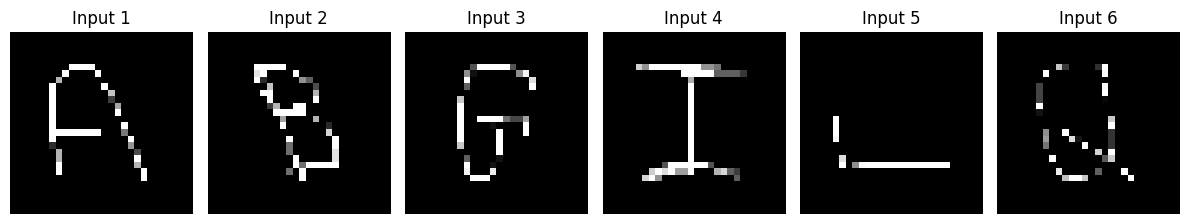

Total processed letters: 6


In [20]:

processed_letters = []

for x, y, w, h in letter_boxes:

    letter = threshold[y:y+h, x:x+w]

    # Add padding
    letter = cv2.copyMakeBorder(
        letter, 5, 5, 5, 5,
        cv2.BORDER_CONSTANT,
        value=0
    )

    # Resize while maintaining aspect ratio
    h, w = letter.shape
    scale = 20 / max(h, w)

    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    letter = cv2.resize(letter, (new_w, new_h))

    # Place letter in a 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)

    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = letter

    processed_letters.append(canvas)

# Convert to model input format
processed_letters = np.array(
    processed_letters,
    dtype=np.float32
) / 255.0

processed_letters = processed_letters.reshape(-1, 28, 28, 1)

# Display processed letters in reading order
plt.figure(figsize=(12, 3))

for i, letter in enumerate(processed_letters):
    plt.subplot(1, 6, i + 1)
    plt.imshow(letter.squeeze(), cmap="gray")
    plt.title(f"Input {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total processed letters:", len(processed_letters))


## 13. Optional: Create an interactive Gradio demo

This demo accepts **one handwritten uppercase letter per image**. It uses the same thresholding, padding, resizing, and normalization approach as the custom-image test above.

Run this section after the model has been trained or loaded from Drive.

In [21]:
!pip -q install gradio
import gradio as gr

In [22]:
def predict_single_letter(uploaded_image):
    if uploaded_image is None:
        return "Please upload an image.", {}

    gray = cv2.cvtColor(uploaded_image, cv2.COLOR_RGB2GRAY)

    _, threshold_image = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        threshold_image,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    contours = [
        contour for contour in contours
        if cv2.boundingRect(contour)[2] > 10
        and cv2.boundingRect(contour)[3] > 10
    ]

    if not contours:
        return "No letter detected.", {}

    contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(contour)
    letter = threshold_image[y:y+h, x:x+w]

    letter = cv2.copyMakeBorder(
        letter, 5, 5, 5, 5,
        cv2.BORDER_CONSTANT,
        value=0
    )

    h, w = letter.shape
    scale = 20 / max(h, w)
    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))
    letter = cv2.resize(letter, (new_w, new_h))

    canvas = np.zeros((28, 28), dtype=np.uint8)
    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2
    canvas[y_offset:y_offset+new_h, x_offset:x_offset+new_w] = letter

    model_input = canvas.astype(np.float32).reshape(1, 28, 28, 1) / 255.0
    probabilities = model.predict(model_input, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_letter = string.ascii_uppercase[predicted_index]
    confidence = float(np.max(probabilities))

    class_probabilities = {
        string.ascii_uppercase[i]: float(probabilities[i])
        for i in range(26)
    }

    return (
        f"Predicted letter: {predicted_letter} | Confidence: {confidence:.2%}",
        class_probabilities
    )

In [23]:
import os

model_path = "/content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model.keras"

print("Model file exists:", os.path.exists(model_path))

Model file exists: True


In [24]:
import os

project_folder = "/content/drive/MyDrive/Handwritten_Alphabet_Project"

print("Folder exists:", os.path.exists(project_folder))

if os.path.exists(project_folder):
    print("\nFiles inside project folder:")
    for file in os.listdir(project_folder):
        print(file)

Folder exists: True

Files inside project folder:
handwritten_alphabet_model_backup.keras
handwritten_alphabet_model.keras
Handwritten_Alphabet_Recognition_Raza_Ali_Clean.ipynb
Screenshot 2026-11-20 034121.png


In [25]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Amber ZIA (New Campaigns)', 'Document from Raza Ali (3)', 'Document from Raza Ali (2)', 'Document from Raza Ali (1)', 'GHALIB QURESHI', 'Document from Raza Ali', 'AMBER ZIA COUTURE ', 'Colab Notebooks', 'Handwritten_Alphabet_Project']


In [27]:
import os

project_folder = "/content/drive/MyDrive/Handwritten_Alphabet_Project"

print("Files inside Handwritten_Alphabet_Project:")

for file in os.listdir(project_folder):
    print(file)

Files inside Handwritten_Alphabet_Project:
handwritten_alphabet_model_backup.keras
handwritten_alphabet_model.keras
Handwritten_Alphabet_Recognition_Raza_Ali_Clean.ipynb
Screenshot 2026-11-20 034121.png


In [28]:
from tensorflow import keras

model_path = "/content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model.keras"

model = keras.models.load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [29]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 681,296 (2.60 MB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 454,198 (1.73 MB)

In [30]:
predictions = model.predict(processed_letters, verbose=0)

for i, prediction in enumerate(predictions):
    predicted_index = int(np.argmax(prediction))
    predicted_letter = string.ascii_uppercase[predicted_index]
    confidence = float(np.max(prediction)) * 100

    print(f"Letter {i + 1}: {predicted_letter} | Confidence: {confidence:.2f}%")

Letter 1: A | Confidence: 51.49%
Letter 2: E | Confidence: 25.49%
Letter 3: G | Confidence: 58.45%
Letter 4: I | Confidence: 96.82%
Letter 5: L | Confidence: 82.63%
Letter 6: E | Confidence: 20.22%


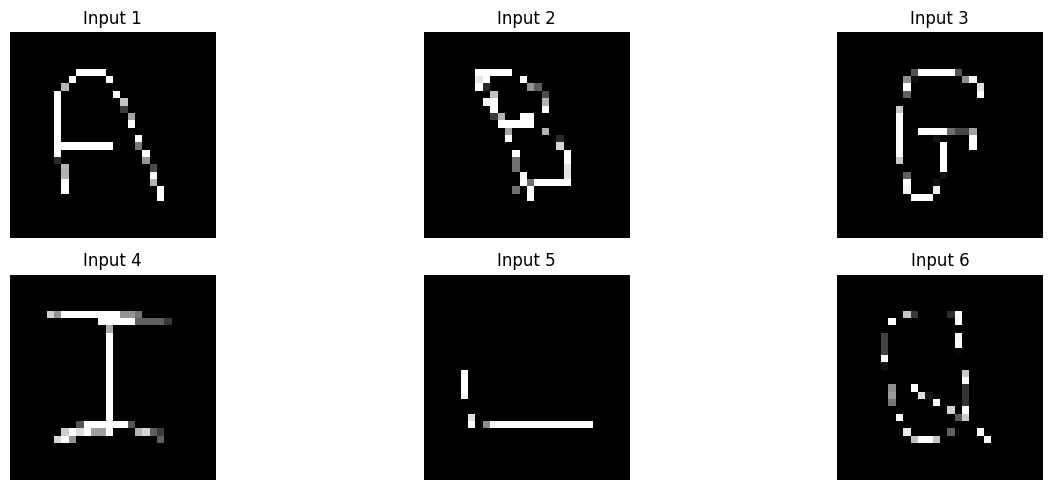

In [31]:
plt.figure(figsize=(14, 5))

for i, letter in enumerate(processed_letters):
    plt.subplot(2, 3, i + 1)
    plt.imshow(letter.squeeze(), cmap="gray")
    plt.title(f"Input {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
!pip install -q importlib_resources tensorflow-datasets

In [33]:

import tensorflow_datasets as tfds

train_raw, dataset_info = tfds.load(
    'emnist/letters',
    split='train',
    as_supervised=True,
    with_info=True
)

print("Training dataset loaded:", dataset_info.splits['train'].num_examples)


Training dataset loaded: 88800


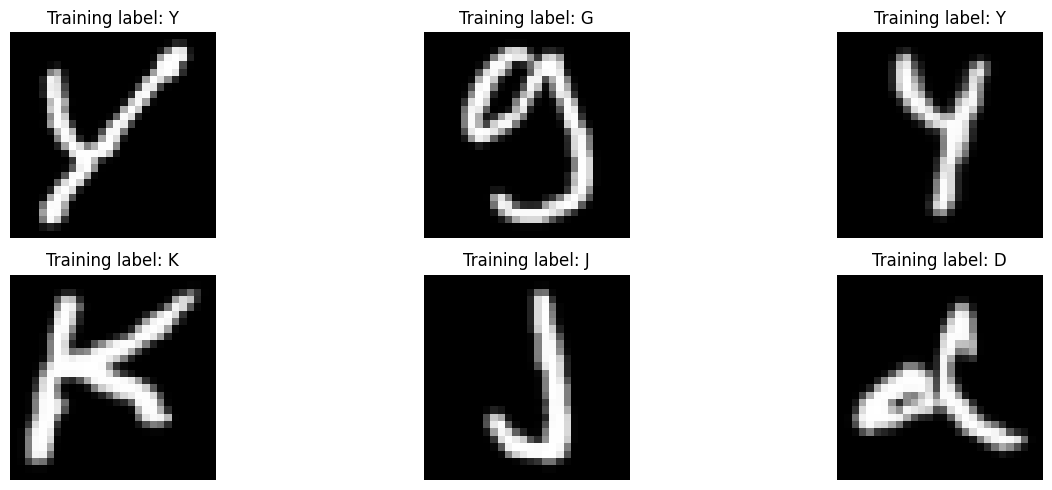

In [34]:
plt.figure(figsize=(14, 5))

for i, (image, label) in enumerate(train_raw.take(6)):
    image = tf.transpose(image, perm=[1, 0, 2])

    plt.subplot(2, 3, i + 1)
    plt.imshow(image.numpy().squeeze(), cmap="gray")
    plt.title(f"Training label: {string.ascii_uppercase[int(label) - 1]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

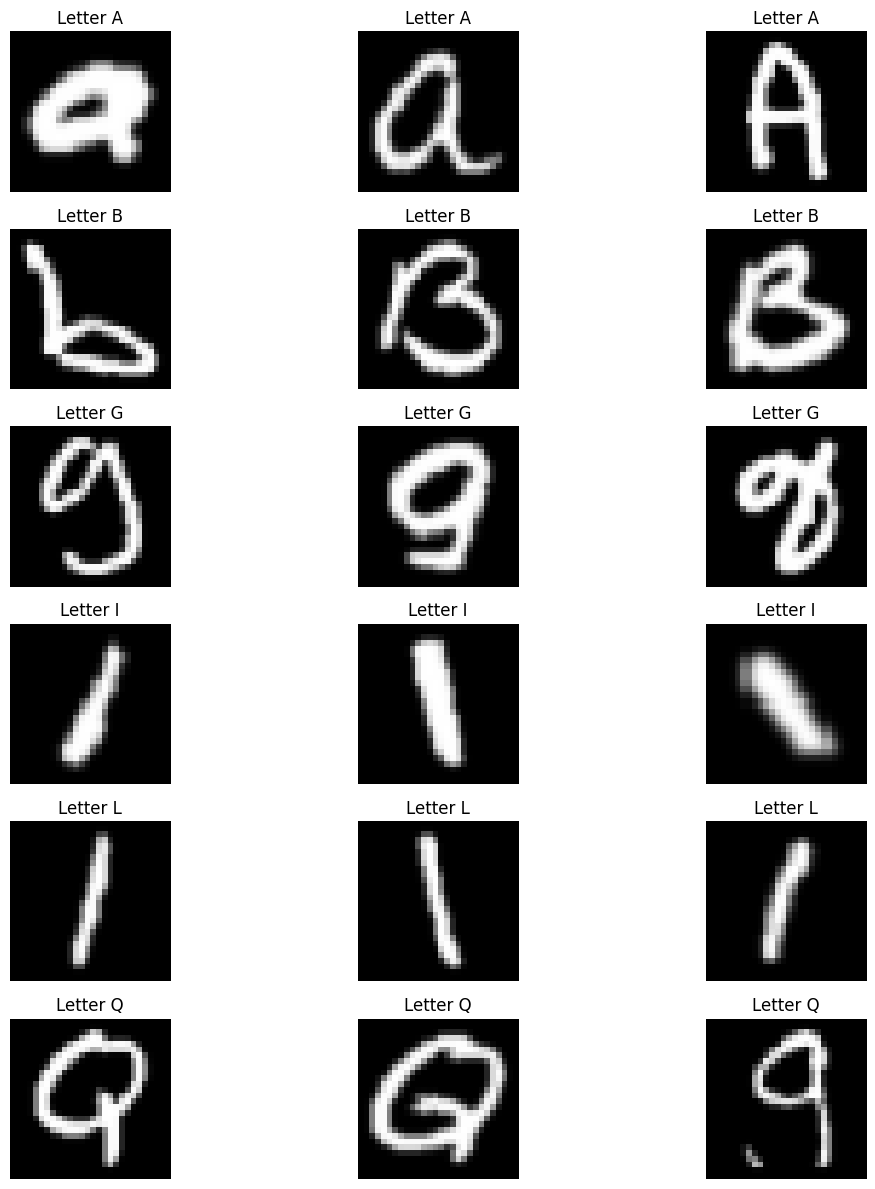

In [35]:

import matplotlib.pyplot as plt
import tensorflow as tf
import string

target_letters = ["A", "B", "G", "I", "L", "Q"]

plt.figure(figsize=(12, 12))

plot_index = 1

for letter in target_letters:

    class_id = string.ascii_uppercase.index(letter) + 1

    letter_examples = train_raw.filter(
        lambda image, label: tf.equal(label, class_id)
    ).take(3)

    for image, label in letter_examples:

        image = tf.transpose(image, perm=[1, 0, 2])

        plt.subplot(6, 3, plot_index)
        plt.imshow(image.numpy().squeeze(), cmap="gray")
        plt.title(f"Letter {letter}")
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()


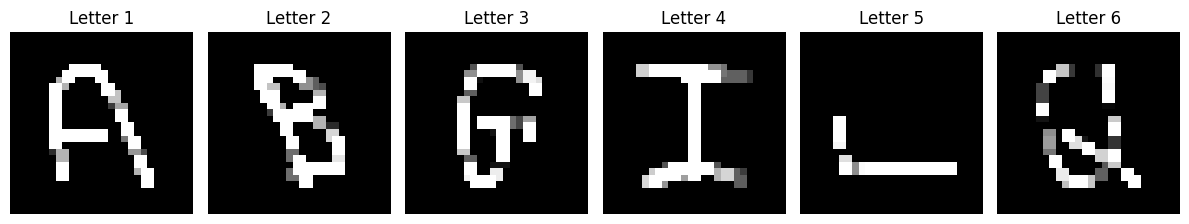

In [36]:

# Create a separate copy of the processed letters
thicker_letters = []

kernel = np.ones((2, 2), np.uint8)

for letter in processed_letters:

    image = (letter.squeeze() * 255).astype(np.uint8)

    # Slightly increase stroke thickness
    image = cv2.dilate(image, kernel, iterations=1)

    thicker_letters.append(image)

thicker_letters = np.array(
    thicker_letters,
    dtype=np.float32
) / 255.0

thicker_letters = thicker_letters.reshape(-1, 28, 28, 1)

# Display the modified letters
plt.figure(figsize=(12, 3))

for i, letter in enumerate(thicker_letters):
    plt.subplot(1, 6, i + 1)
    plt.imshow(letter.squeeze(), cmap="gray")
    plt.title(f"Letter {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [37]:
thick_predictions = model.predict(thicker_letters, verbose=0)

for i, prediction in enumerate(thick_predictions):
    index = np.argmax(prediction)
    letter = string.ascii_uppercase[index]
    confidence = np.max(prediction) * 100

    print(f"Letter {i + 1}: {letter} | Confidence: {confidence:.2f}%")

Letter 1: A | Confidence: 94.47%
Letter 2: B | Confidence: 82.34%
Letter 3: G | Confidence: 94.30%
Letter 4: I | Confidence: 96.70%
Letter 5: L | Confidence: 95.43%
Letter 6: D | Confidence: 48.71%


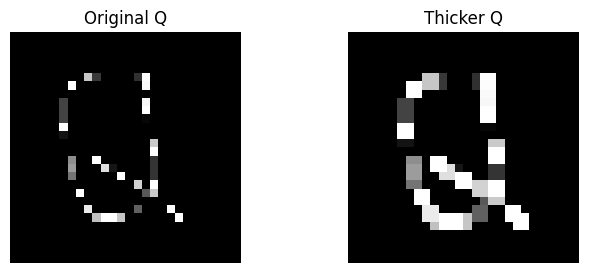

In [38]:
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.imshow(processed_letters[5].squeeze(), cmap="gray")
plt.title("Original Q")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(thicker_letters[5].squeeze(), cmap="gray")
plt.title("Thicker Q")
plt.axis("off")

plt.show()

In [39]:

original_q = model.predict(
    processed_letters[5:6],
    verbose=0
)[0]

thicker_q = model.predict(
    thicker_letters[5:6],
    verbose=0
)[0]

print("Original Q — top predictions:")
for i in np.argsort(original_q)[-5:][::-1]:
    print(f"{string.ascii_uppercase[i]}: {original_q[i] * 100:.2f}%")

print("\nThicker Q — top predictions:")
for i in np.argsort(thicker_q)[-5:][::-1]:
    print(f"{string.ascii_uppercase[i]}: {thicker_q[i] * 100:.2f}%")


Original Q — top predictions:
E: 20.22%
L: 16.69%
C: 14.68%
S: 8.91%
K: 7.58%

Thicker Q — top predictions:
D: 48.71%
Y: 21.02%
U: 10.79%
G: 4.29%
H: 4.08%


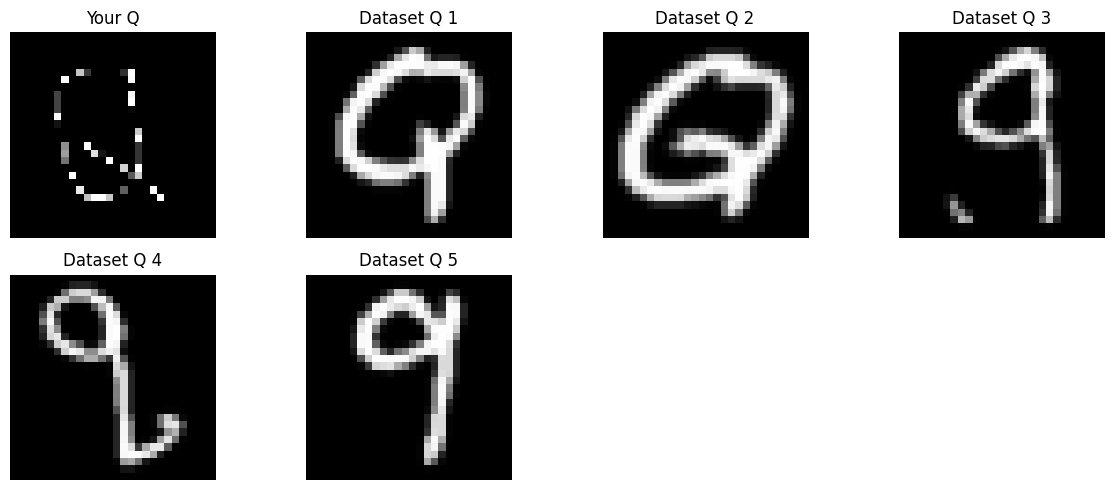

In [40]:

plt.figure(figsize=(12, 5))

# Your original Q
plt.subplot(2, 4, 1)
plt.imshow(processed_letters[5].squeeze(), cmap="gray")
plt.title("Your Q")
plt.axis("off")

# Five Q examples from EMNIST
q_class_id = 17  # Q is the 17th letter

q_examples = train_raw.filter(
    lambda image, label: tf.equal(label, q_class_id)
).take(5)

for i, (image, label) in enumerate(q_examples):
    image = tf.transpose(image, perm=[1, 0, 2])

    plt.subplot(2, 4, i + 2)
    plt.imshow(image.numpy().squeeze(), cmap="gray")
    plt.title(f"Dataset Q {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


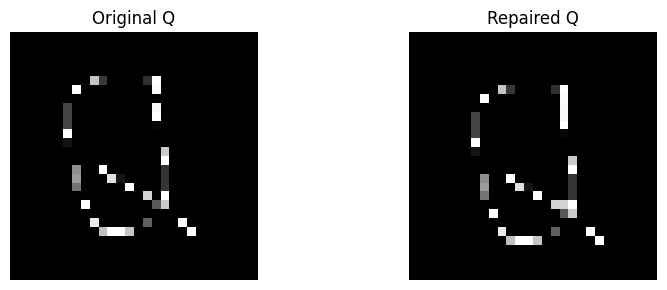

In [41]:

# Take a separate copy of the original Q
original_q_image = (
    processed_letters[5].squeeze() * 255
).astype(np.uint8)

# Small kernel to connect nearby gaps
kernel = np.ones((2, 2), np.uint8)

# Close small gaps
repaired_q_image = cv2.morphologyEx(
    original_q_image,
    cv2.MORPH_CLOSE,
    kernel
)

# Display comparison
plt.figure(figsize=(9, 3))

plt.subplot(1, 2, 1)
plt.imshow(original_q_image, cmap="gray")
plt.title("Original Q")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(repaired_q_image, cmap="gray")
plt.title("Repaired Q")
plt.axis("off")

plt.tight_layout()
plt.show()


In [42]:

repaired_q_input = (
    repaired_q_image.astype(np.float32) / 255.0
).reshape(1, 28, 28, 1)

repaired_prediction = model.predict(
    repaired_q_input,
    verbose=0
)[0]

for i in np.argsort(repaired_prediction)[-5:][::-1]:
    print(
        f"{string.ascii_uppercase[i]}: "
        f"{repaired_prediction[i] * 100:.2f}%"
    )


C: 22.35%
L: 22.03%
S: 18.61%
Y: 7.51%
E: 5.63%


In [43]:
!pip install -q gradio

import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


In [44]:
demo = gr.Interface(
    fn=predict_single_letter,
    inputs=gr.Image(type='numpy', label='Upload one handwritten uppercase letter'),
    outputs=[
        gr.Textbox(label='Prediction'),
        gr.Label(label='Class probabilities', num_top_classes=5)
    ],
    title='Handwritten Alphabet Recognition',
    description='Upload an image containing one handwritten uppercase English letter (A–Z).'
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0e37d04ab2f48d2a09.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. Reload the saved model later

If the Colab runtime disconnects, reconnect Google Drive and load the saved model with this cell. You do not need to train again if the model file exists.

In [45]:
from google.colab import drive
drive.mount('/content/drive')

model_path = '/content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model.keras'

model = keras.models.load_model(model_path)
print("Model loaded successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully.


In [46]:
import os
import shutil

model_path = "/content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

Model exists: True
Model size: 2.64 MB


In [47]:
backup_path = "/content/drive/MyDrive/Handwritten_Alphabet_Project/handwritten_alphabet_model_backup.keras"

shutil.copy2(model_path, backup_path)

print("Model backup created:", os.path.exists(backup_path))

Model backup created: True


## 15. Project completion checklist

- [ ] Dataset loaded and inspected
- [ ] Images and labels preprocessed
- [ ] Training, validation, and test sets prepared
- [ ] CNN built and trained
- [ ] Model evaluated on held-out test data
- [ ] Classification report and confusion matrix reviewed
- [ ] Custom handwritten images tested
- [ ] Trained model saved to Google Drive
- [ ] Gradio demo launched and tested

**Reminder:** Report the test accuracy produced by your final run. Do not report the accuracy from an earlier training run if the model was retrained.